In [1]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("data/raw/ not found above " + str(start))

ROOT = find_project_root()
PROC_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

with open(PROC_DIR / "preprocessing_config.json") as f:
    config = json.load(f)

df = pd.read_csv(PROC_DIR / "train_engineered.csv")

train_df = df[df["unit"].isin(config["train_engine_ids"])]
val_df = df[df["unit"].isin(config["val_engine_ids"])]

feature_cols = [c for c in df.columns if c not in ["unit", "cycle", "RUL"]]
X_train, y_train = train_df[feature_cols], train_df["RUL"]
X_val, y_val = val_df[feature_cols], val_df["RUL"]

print("features:", len(feature_cols))
print("train:", X_train.shape, "| val:", X_val.shape)
print("train engines:", train_df["unit"].nunique(), "| val engines:", val_df["unit"].nunique())

features: 56
train: (16561, 56) | val: (4070, 56)
train engines: 80 | val engines: 20


In [2]:
def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)      # d > 0 means predicted too much life
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def evaluate(model, X, y, name, subset):
    pred = model.predict(X)
    return {
        "model": name,
        "subset": subset,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": float(np.sqrt(mean_squared_error(y, pred))),
        "NASA_score": nasa_score(y, pred),
        "n_rows": len(y),
    }

In [3]:
models = {
    "Dummy (mean RUL)": DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
}

rows = []
mask_le145 = (y_val <= 145).to_numpy()

for name, model in models.items():
    model.fit(X_train, y_train)        # the scaler is fit inside the pipeline, on training engines only
    rows.append(evaluate(model, X_val, y_val, name, "all val rows"))
    rows.append(evaluate(model, X_val[mask_le145], y_val[mask_le145], name, "val rows, RUL <= 145"))

results = pd.DataFrame(rows)
print(results.round(2).to_string(index=False))

results.assign(experiment="baseline_unclipped_w10").to_csv(RESULTS_DIR / "experiments.csv", index=False)

            model               subset   MAE  RMSE  NASA_score  n_rows
 Dummy (mean RUL)         all val rows 55.36 65.72 19351068.76    4070
 Dummy (mean RUL) val rows, RUL <= 145 45.37 55.42 10700250.17    2909
Linear Regression         all val rows 29.06 36.74  4633087.22    4070
Linear Regression val rows, RUL <= 145 25.00 30.07   148325.34    2909


  true RUL bin   n  mean signed error  MAE  NASA score
(-0.001, 25.0] 520               -5.9 19.7      7520.4
  (25.0, 50.0] 500               24.0 25.3     21363.3
  (50.0, 75.0] 500               31.1 31.6     55232.3
 (75.0, 100.0] 500               27.0 29.3     45829.2
(100.0, 125.0] 500               15.5 23.7     14100.8
(125.0, 150.0] 484                0.2 19.3      5021.4
(150.0, 200.0] 673              -24.1 28.8   3332522.2
(200.0, 400.0] 393              -61.4 61.9   1151497.6

Negative predictions: 208 of 4070


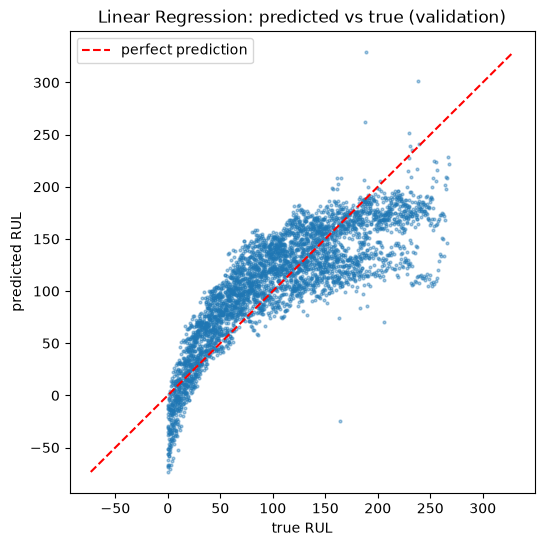

In [4]:
lr = models["Linear Regression"]
pred = lr.predict(X_val)
y_true = y_val.to_numpy()
err = pred - y_true      # positive = predicted too much remaining life

bins = [0, 25, 50, 75, 100, 125, 150, 200, 400]
labels = pd.cut(pd.Series(y_true), bins=bins, include_lowest=True)

rows = []
for b in labels.cat.categories:
    m = (labels == b).to_numpy()
    rows.append({
        "true RUL bin": str(b),
        "n": int(m.sum()),
        "mean signed error": err[m].mean(),
        "MAE": np.abs(err[m]).mean(),
        "NASA score": nasa_score(y_true[m], pred[m]),
    })
print(pd.DataFrame(rows).round(1).to_string(index=False))
print("\nNegative predictions:", int((pred < 0).sum()), "of", len(pred))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_true, pred, s=4, alpha=0.4)
lim = [min(pred.min(), 0), max(y_true.max(), pred.max())]
ax.plot(lim, lim, color="red", linestyle="--", label="perfect prediction")
ax.set_xlabel("true RUL")
ax.set_ylabel("predicted RUL")
ax.set_title("Linear Regression: predicted vs true (validation)")
ax.legend()
plt.show()

In [5]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    max_features=0.5,
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)

rf_rows = [
    evaluate(rf, X_val, y_val, "Random Forest", "all val rows"),
    evaluate(rf, X_val[mask_le145], y_val[mask_le145], "Random Forest", "val rows, RUL <= 145"),
]
print(pd.DataFrame(rf_rows).round(2).to_string(index=False))

pd.concat([results.assign(experiment="baseline_unclipped_w10"),
           pd.DataFrame(rf_rows).assign(experiment="baseline_unclipped_w10")]
          ).to_csv(RESULTS_DIR / "experiments.csv", index=False)

pred_rf = rf.predict(X_val)
err_rf = pred_rf - y_true
rows = []
for b in labels.cat.categories:
    m = (labels == b).to_numpy()
    rows.append({"true RUL bin": str(b), "n": int(m.sum()),
                 "mean signed error": err_rf[m].mean(),
                 "MAE": np.abs(err_rf[m]).mean()})
print()
print(pd.DataFrame(rows).round(1).to_string(index=False))
print("\nNegative predictions:", int((pred_rf < 0).sum()))

        model               subset   MAE  RMSE  NASA_score  n_rows
Random Forest         all val rows 21.69 30.62   551863.44    4070
Random Forest val rows, RUL <= 145 17.14 24.93   348984.59    2909

  true RUL bin   n  mean signed error  MAE
(-0.001, 25.0] 520                2.8  3.6
  (25.0, 50.0] 500                8.7 10.6
  (50.0, 75.0] 500               16.4 20.9
 (75.0, 100.0] 500               23.0 28.3
(100.0, 125.0] 500               14.5 22.4
(125.0, 150.0] 484                5.3 17.8
(150.0, 200.0] 673              -15.8 23.3
(200.0, 400.0] 393              -52.8 53.4

Negative predictions: 0


In [6]:
cap_rows = []
bin_tables = {}
for cap in [None, 150, 130, 110]:
    y_fit = y_train if cap is None else y_train.clip(upper=cap)
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                              max_features=0.5, n_jobs=-1, random_state=42)
    m.fit(X_train, y_fit)
    name = f"RF cap={cap}"
    cap_rows.append(evaluate(m, X_val, y_val, name, "all val rows"))
    cap_rows.append(evaluate(m, X_val[mask_le145], y_val[mask_le145], name, "val rows, RUL <= 145"))

    p = m.predict(X_val); e = p - y_true
    bin_tables[name] = [e[(labels == b).to_numpy()].mean() for b in labels.cat.categories]

cap_df = pd.DataFrame(cap_rows)
print(cap_df.round(2).to_string(index=False))
print()
print(pd.DataFrame(bin_tables, index=[str(b) for b in labels.cat.categories]).round(1))

cap_df.assign(experiment="clipping_rf_w10").to_csv(RESULTS_DIR / "experiments_clipping.csv", index=False)

      model               subset   MAE  RMSE  NASA_score  n_rows
RF cap=None         all val rows 21.69 30.62   551863.44    4070
RF cap=None val rows, RUL <= 145 17.14 24.93   348984.59    2909
 RF cap=150         all val rows 24.78 36.42  1502122.05    4070
 RF cap=150 val rows, RUL <= 145 12.96 18.51    46415.75    2909
 RF cap=130         all val rows 27.97 41.73  3579201.14    4070
 RF cap=130 val rows, RUL <= 145 12.37 16.98    22625.45    2909
 RF cap=110         all val rows 32.95 49.39 11709172.43    4070
 RF cap=110 val rows, RUL <= 145 13.10 17.70    14766.50    2909

                RF cap=None  RF cap=150  RF cap=130  RF cap=110
(-0.001, 25.0]          2.8         2.7         2.6         2.6
(25.0, 50.0]            8.7         8.1         7.9         7.6
(50.0, 75.0]           16.4        14.2        12.5         9.4
(75.0, 100.0]          23.0        15.3        10.6         3.6
(100.0, 125.0]         14.5         3.4        -3.3       -13.5
(125.0, 150.0]          5.3   

In [7]:
from sklearn.model_selection import GroupKFold

all_train = df[df["unit"].isin(config["train_engine_ids"] + config["val_engine_ids"])]
X_all = all_train[feature_cols]
y_all = all_train["RUL"]
groups = all_train["unit"]

gkf = GroupKFold(n_splits=5)
rows = []
for cap in [None, 150, 130, 110]:
    fold_mae = []
    for tr_idx, va_idx in gkf.split(X_all, y_all, groups):
        y_fit = y_all.iloc[tr_idx]
        if cap is not None:
            y_fit = y_fit.clip(upper=cap)
        m = RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                  max_features=0.5, n_jobs=-1, random_state=42)
        m.fit(X_all.iloc[tr_idx], y_fit)
        yv = y_all.iloc[va_idx]
        keep = (yv <= 145).to_numpy()
        p = m.predict(X_all.iloc[va_idx][keep])
        fold_mae.append(mean_absolute_error(yv[keep], p))
    rows.append({"cap": cap, "mean_MAE": np.mean(fold_mae), "std_MAE": np.std(fold_mae),
                 "folds": [round(x, 2) for x in fold_mae]})
print(pd.DataFrame(rows).round(2).to_string(index=False))

  cap  mean_MAE  std_MAE                               folds
  NaN     20.32     2.48  [17.58, 17.07, 21.81, 22.13, 23.0]
150.0     15.24     0.91 [14.79, 13.77, 16.45, 15.66, 15.54]
130.0     13.99     0.52  [13.93, 13.33, 14.9, 14.12, 13.68]
110.0     14.42     0.29  [14.54, 14.33, 14.87, 14.4, 13.96]


In [8]:
cv_table = pd.DataFrame(rows)
cv_table["folds"] = cv_table["folds"].astype(str)
cv_table.to_csv(RESULTS_DIR / "cv_clipping_rf_w10.csv", index=False)

config["training_target"] = {
    "rul_cap": 130,
    "basis": "5-fold GroupKFold by engine, RF, scored on RUL<=145 rows: cap130 mean MAE 13.99 vs 14.42 (110), 15.24 (150), 20.32 (none)",
    "validation_scored_against": "true unclipped RUL",
}
with open(PROC_DIR / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)
print("logged")

logged


In [16]:
from xgboost import XGBRegressor

CAP = 130
y_train_c = y_train.clip(upper=CAP)

models_c = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           max_features=0.5, n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                            subsample=0.8, colsample_bytree=0.8,
                            device="cuda", random_state=42),       # Changed n_jobs=-1 to device="cuda"
}

rows = []
for name, model in models_c.items():
    model.fit(X_train, y_train_c)
    rows.append(evaluate(model, X_val[mask_le145], y_val[mask_le145], f"{name} (cap130)", "val rows, RUL <= 145"))
cmp_df = pd.DataFrame(rows)
print(cmp_df.round(2).to_string(index=False))
cmp_df.to_csv(RESULTS_DIR / "model_comparison_cap130.csv", index=False)

                     model               subset   MAE  RMSE  NASA_score  n_rows
Linear Regression (cap130) val rows, RUL <= 145 16.83 20.61    22389.36    2909
    Random Forest (cap130) val rows, RUL <= 145 12.37 16.98    22625.45    2909
          XGBoost (cap130) val rows, RUL <= 145 12.14 16.55    20099.09    2909


In [14]:
CAP = 130
gkf = GroupKFold(n_splits=5)

def make_models():
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                               max_features=0.5, n_jobs=-1, random_state=42),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                                subsample=0.8, colsample_bytree=0.8,
                                device="cuda", random_state=42),       # Changed n_jobs=-1 to device="cuda"
    }

scores = {name: {"MAE": [], "RMSE": []} for name in make_models()}

for tr_idx, va_idx in gkf.split(X_all, y_all, groups):
    y_fit = y_all.iloc[tr_idx].clip(upper=CAP)
    yv = y_all.iloc[va_idx]
    keep = (yv <= 145).to_numpy()
    Xv, yv = X_all.iloc[va_idx][keep], yv[keep]
    for name, m in make_models().items():
        m.fit(X_all.iloc[tr_idx], y_fit)
        p = m.predict(Xv)
        scores[name]["MAE"].append(mean_absolute_error(yv, p))
        scores[name]["RMSE"].append(float(np.sqrt(mean_squared_error(yv, p))))

summary = pd.DataFrame({
    name: {"MAE mean": np.mean(s["MAE"]), "MAE std": np.std(s["MAE"]),
           "RMSE mean": np.mean(s["RMSE"]), "RMSE std": np.std(s["RMSE"])}
    for name, s in scores.items()
}).T
print(summary.round(2))

print("\nPer-fold MAE:")
print(pd.DataFrame({n: np.round(s["MAE"], 2) for n, s in scores.items()}))

diff = np.array(scores["XGBoost"]["MAE"]) - np.array(scores["Random Forest"]["MAE"])
print("\nXGBoost minus RF, MAE per fold:", np.round(diff, 2))

summary.to_csv(RESULTS_DIR / "cv_model_comparison_cap130.csv")

                   MAE mean  MAE std  RMSE mean  RMSE std
Linear Regression     18.36     0.99      22.43      1.11
Random Forest         13.99     0.52      18.82      0.36
XGBoost               13.53     0.31      18.25      0.20

Per-fold MAE:
   Linear Regression  Random Forest  XGBoost
0              17.95          13.93    13.53
1              18.18          13.33    13.07
2              19.17          14.90    14.03
3              16.83          14.12    13.59
4              19.66          13.68    13.44

XGBoost minus RF, MAE per fold: [-0.4  -0.26 -0.87 -0.53 -0.24]


In [19]:
feature_sensors = config["feature_sensors"]
def cv_xgb(X, label):
    fold_mae = []
    for tr_idx, va_idx in gkf.split(X, y_all, groups):
        y_fit = y_all.iloc[tr_idx].clip(upper=CAP)
        yv = y_all.iloc[va_idx]
        keep = (yv <= 145).to_numpy()
        m = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                         subsample=0.8, colsample_bytree=0.8,
                         device="cuda", random_state=42)       # Changed n_jobs=-1 to device="cuda"
        m.fit(X.iloc[tr_idx], y_fit)
        fold_mae.append(mean_absolute_error(yv[keep], m.predict(X.iloc[va_idx][keep])))
    return {"variant": label, "n_features": X.shape[1],
            "MAE mean": np.mean(fold_mae), "MAE std": np.std(fold_mae),
            "folds": [round(x, 2) for x in fold_mae]}

base_cols = feature_cols
no_9_14 = [c for c in base_cols if not (c.startswith("sensor_9") or c.startswith("sensor_14"))]
raw_only = [c for c in base_cols if c in feature_sensors]
no_slope = [c for c in base_cols if "_slope" not in c]
no_std = [c for c in base_cols if "_std" not in c]

variants = {
    "baseline (56)": X_all[base_cols],
    "drop sensor_9 and sensor_14": X_all[no_9_14],
    "raw sensors only": X_all[raw_only],
    "no slope features": X_all[no_slope],
    "no std features": X_all[no_std],
    "baseline + cycle": X_all[base_cols].assign(cycle=all_train["cycle"].values),
}

abl = pd.DataFrame([cv_xgb(X, name) for name, X in variants.items()])
print(abl.round(2).to_string(index=False))
abl.assign(folds=abl["folds"].astype(str)).to_csv(RESULTS_DIR / "ablation_xgb_cap130.csv", index=False)

                    variant  n_features  MAE mean  MAE std                               folds
              baseline (56)          56     13.53     0.31 [13.53, 13.07, 14.03, 13.59, 13.44]
drop sensor_9 and sensor_14          48     14.21     0.63 [14.39, 13.77, 15.14, 13.31, 14.46]
           raw sensors only          14     16.48     0.65 [16.71, 15.64, 17.58, 16.18, 16.28]
          no slope features          42     16.65     0.65 [17.08, 15.86, 17.66, 16.49, 16.16]
            no std features          42     13.48     0.43 [13.46, 12.83, 14.17, 13.61, 13.32]
           baseline + cycle          57     12.33     0.48  [12.33, 11.88, 12.71, 11.74, 13.0]


In [20]:
feature_sensors = config["feature_sensors"]
raw_cols = list(feature_sensors)
mean_cols = [f"{s}_mean10" for s in feature_sensors]
slope_cols = [f"{s}_slope20" for s in feature_sensors]
assert all(c in X_all.columns for c in raw_cols + mean_cols + slope_cols)

def with_cycle(cols):
    return X_all[cols].assign(cycle=all_train["cycle"].values)

variants2 = {
    "raw + slope": X_all[raw_cols + slope_cols],
    "raw + mean": X_all[raw_cols + mean_cols],
    "raw + cycle": with_cycle(raw_cols),
    "raw + slope + cycle": with_cycle(raw_cols + slope_cols),
    "raw + mean + slope + cycle (no std)": with_cycle(raw_cols + mean_cols + slope_cols),
}

abl2 = pd.DataFrame([cv_xgb(X, name) for name, X in variants2.items()])
print(abl2.round(2).to_string(index=False))
abl2.assign(folds=abl2["folds"].astype(str)).to_csv(RESULTS_DIR / "ablation2_xgb_cap130.csv", index=False)

                            variant  n_features  MAE mean  MAE std                               folds
                        raw + slope          28     13.50     0.33 [13.77, 13.05, 13.89, 13.17, 13.62]
                         raw + mean          28     16.67     0.87  [17.14, 15.62, 18.09, 16.39, 16.1]
                        raw + cycle          15     14.86     0.86 [15.44, 14.01, 15.84, 13.64, 15.35]
                raw + slope + cycle          29     12.41     0.56 [13.04, 11.69, 12.86, 11.81, 12.66]
raw + mean + slope + cycle (no std)          43     12.20     0.42  [12.08, 11.75, 12.58, 11.8, 12.81]


In [21]:
def _slope(a):
    x = np.arange(len(a)); xm = x.mean()
    return ((x - xm) * (a - a.mean())).sum() / ((x - xm) ** 2).sum()

def slope_block(df, sensors, window):
    g = df.sort_values(["unit", "cycle"]).groupby("unit")[sensors]
    out = g.rolling(window, min_periods=2).apply(_slope, raw=True)
    out = out.reset_index(level=0, drop=True).add_suffix(f"_slope{window}")
    return out.fillna(0.0).loc[df.index]          # NaNs are cycle 1 only, as verified before

base_df = all_train[["unit", "cycle"] + raw_cols]
sl = {w: slope_block(base_df, raw_cols, w) for w in [10, 30, 40]}
sl[20] = X_all[slope_cols]

def build(ws):
    return pd.concat([X_all[raw_cols]] + [sl[w] for w in ws], axis=1).assign(cycle=all_train["cycle"].values)

variants3 = {
    "raw + slope10 + cycle": build([10]),
    "raw + slope20 + cycle (check = 12.41)": build([20]),
    "raw + slope30 + cycle": build([30]),
    "raw + slope40 + cycle": build([40]),
    "raw + slope10+20+30 + cycle": build([10, 20, 30]),
}
abl3 = pd.DataFrame([cv_xgb(X, name) for name, X in variants3.items()])
print(abl3.round(2).to_string(index=False))
abl3.assign(folds=abl3["folds"].astype(str)).to_csv(RESULTS_DIR / "ablation3_slope_window.csv", index=False)

                              variant  n_features  MAE mean  MAE std                               folds
                raw + slope10 + cycle          29     14.49     0.71 [14.97, 13.65, 15.27, 13.62, 14.94]
raw + slope20 + cycle (check = 12.41)          29     12.41     0.56 [13.04, 11.69, 12.86, 11.81, 12.66]
                raw + slope30 + cycle          29     10.70     0.54  [11.31, 9.99, 10.86, 10.14, 11.18]
                raw + slope40 + cycle          29      9.45     0.30      [9.95, 9.01, 9.49, 9.46, 9.36]
          raw + slope10+20+30 + cycle          57     10.72     0.54 [11.36, 10.02, 10.92, 10.16, 11.16]


In [22]:
sl.update({w: slope_block(base_df, raw_cols, w) for w in [50, 60, 80]})

variants4 = {
    "raw + slope40 + cycle (check = 9.45)": build([40]),
    "raw + slope50 + cycle": build([50]),
    "raw + slope60 + cycle": build([60]),
    "raw + slope80 + cycle": build([80]),
}
abl4 = pd.DataFrame([cv_xgb(X, name) for name, X in variants4.items()])
print(abl4.round(2).to_string(index=False))

# Error by cycle bucket, to see where long windows help or hurt
def cv_by_cycle(X, label):
    rows = []
    for tr_idx, va_idx in gkf.split(X, y_all, groups):
        y_fit = y_all.iloc[tr_idx].clip(upper=CAP)
        m = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                         subsample=0.8, colsample_bytree=0.8,
                         device="cuda", random_state=42)
        m.fit(X.iloc[tr_idx], y_fit)
        v = all_train.iloc[va_idx]
        keep = (v["RUL"] <= 145).to_numpy()
        p = m.predict(X.iloc[va_idx][keep])
        rows.append(pd.DataFrame({"cycle": v["cycle"][keep].values,
                                  "abs_err": np.abs(p - v["RUL"][keep].values)}))
    d = pd.concat(rows)
    d["bucket"] = pd.cut(d["cycle"], [0, 50, 100, 150, 400])
    return d.groupby("bucket", observed=True)["abs_err"].mean().rename(label)

print()
print(pd.concat([cv_by_cycle(build([20]), "slope20"),
                 cv_by_cycle(build([40]), "slope40"),
                 cv_by_cycle(build([60]), "slope60")], axis=1).round(2))

                             variant  n_features  MAE mean  MAE std                          folds
raw + slope40 + cycle (check = 9.45)          29      9.45     0.30 [9.95, 9.01, 9.49, 9.46, 9.36]
               raw + slope50 + cycle          29      8.75     0.44 [9.52, 8.21, 8.89, 8.64, 8.49]
               raw + slope60 + cycle          29      8.19     0.45 [8.97, 7.67, 8.35, 8.11, 7.87]
               raw + slope80 + cycle          29      7.84     0.53  [8.73, 7.19, 7.91, 7.99, 7.4]

            slope20  slope40  slope60
bucket                               
(0, 50]       11.66    11.34    11.26
(50, 100]     17.31    14.80    13.30
(100, 150]    13.22     9.00     7.45
(150, 400]     8.82     6.04     4.92


In [23]:
sl.update({w: slope_block(base_df, raw_cols, w) for w in [100, 120, 400]})   # 400 = whole history

def offset_block(df, sensors, k=10):
    """Sensor minus the engine's own early-life baseline. Causal: for cycles <= k the
    baseline is the mean so far, afterwards it is frozen at the mean of the first k cycles."""
    d = df.sort_values(["unit", "cycle"])
    em = d.groupby("unit")[sensors].expanding().mean().reset_index(level=0, drop=True)
    base = em.where(d["cycle"] <= k).groupby(d["unit"]).ffill()
    return (d[sensors] - base).add_suffix(f"_off{k}").loc[df.index]

off10 = offset_block(base_df, raw_cols, 10)

def build2(ws=(), extra=()):
    parts = [X_all[raw_cols]] + [sl[w] for w in ws] + list(extra)
    return pd.concat(parts, axis=1).assign(cycle=all_train["cycle"].values)

variants5 = {
    "raw + slope80 + cycle (check = 7.84)": build2([80]),
    "raw + slope100 + cycle": build2([100]),
    "raw + slope120 + cycle": build2([120]),
    "raw + slope400 (whole history) + cycle": build2([400]),
    "raw + offset10 + cycle": build2(extra=[off10]),
    "raw + offset10 + slope80 + cycle": build2([80], extra=[off10]),
}
abl5 = pd.DataFrame([cv_xgb(X, name) for name, X in variants5.items()])
print(abl5.round(2).to_string(index=False))
abl5.assign(folds=abl5["folds"].astype(str)).to_csv(RESULTS_DIR / "ablation5_plateau_offset.csv", index=False)

                               variant  n_features  MAE mean  MAE std                               folds
  raw + slope80 + cycle (check = 7.84)          29      7.84     0.53       [8.73, 7.19, 7.91, 7.99, 7.4]
                raw + slope100 + cycle          29      8.02     0.53       [8.79, 7.44, 8.1, 8.33, 7.43]
                raw + slope120 + cycle          29      8.19     0.57      [9.03, 7.48, 8.59, 8.17, 7.69]
raw + slope400 (whole history) + cycle          29      7.81     0.70         [8.9, 6.87, 7.9, 8.08, 7.3]
                raw + offset10 + cycle          29     11.06     0.72 [12.35, 10.28, 10.85, 11.22, 10.59]
      raw + offset10 + slope80 + cycle          43      7.84     0.54      [8.71, 7.42, 7.66, 8.18, 7.21]
